# Chapitre 17 - Exercices 17.7 à 17.12

Exercices de programmation sur le modèle graphique gaussien (17.7 : algorithme 17.1,
17.8 : lasso et graphical lasso, 17.9 : algorithme EM avec valeurs manquantes), puis
exercices sur le modèle de Ising (17.10 : nœud constant, 17.11 : lois conditionnelles
logistiques, 17.12 : lien avec la régression de Poisson).

**Données.** Les exercices 17.7–17.9 utilisent les données de cytométrie en flux de
Sachs et al. (11 protéines, 7466 cellules), qui ne sont pas disponibles ici. Nous les
remplaçons par des données gaussiennes **simulées** de même taille dont le vrai graphe
est celui de la figure 17.1 (`g.simulate_cytometry_like`). Les noms de protéines ne
sont que des étiquettes. Avantage : on connaît la vérité et on peut juger les
estimations.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

In [2]:
Xc, Theta_vrai, A_fig = g.simulate_cytometry_like(N=7466, seed=0)
noms, _, pos = g.cytometry_like_graph()
N, p = Xc.shape
Sc = g.empirical_covariance(Xc)
print("N = %d, p = %d, arêtes du graphe de la figure 17.1 : %d" % (N, p, A_fig.sum() // 2))

N = 7466, p = 11, arêtes du graphe de la figure 17.1 : 16


## Exercice 17.7 : Programmer l'algorithme 17.1

**Énoncé.** Écrire un programme mettant en œuvre la procédure de régressions modifiées
(algorithme 17.1) pour ajuster un modèle graphique gaussien dont certaines arêtes sont
imposées absentes. L'essayer sur les données de cytométrie avec le graphe de la
figure 17.1.

**Rappels.** On maximise $\log\det\Theta - \operatorname{tr}(S\Theta)$ sous $\theta_{jk} = 0$ pour
$(j,k)\notin E$. Pour chaque variable $j$, on résout le système réduit aux voisins
$W^*_{11}\beta^* = s^*_{12}$ (éq. (17.19)), on complète $\beta$ par des zéros et on met à jour
$w_{12} = W_{11}\hat\beta$ ; à la fin, $\hat\theta_{22} = 1/(s_{22} - w_{12}^T\hat\beta)$ et
$\hat\theta_{12} = -\hat\beta\,\hat\theta_{22}$ (exercice 17.6).

In [3]:
def algorithme_17_1(S, A, tol=1e-10, max_cycles=1000):
    """Version commentée de l'algorithme 17.1 (régressions modifiées)."""
    p = S.shape[0]
    W = S.copy()                                   # étape 1
    betas = np.zeros((p, p))                       # betas[:, j] : régression de j
    for cycle in range(max_cycles):                # étape 2
        W_avant = W.copy()
        for j in range(p):
            autres = np.array([k for k in range(p) if k != j])
            vois = autres[A[j, autres]]            # variables reliées à j
            beta = np.zeros(p)
            if len(vois) > 0:                      # (b) système réduit (17.19)
                beta[vois] = np.linalg.solve(W[np.ix_(vois, vois)], S[vois, j])
            betas[:, j] = beta
            w12 = W[np.ix_(autres, autres)] @ beta[autres]   # (c)
            W[autres, j] = w12
            W[j, autres] = w12
        if np.abs(W - W_avant).max() < tol:
            break
    Theta = np.zeros((p, p))                       # étape 3
    for j in range(p):
        autres = [k for k in range(p) if k != j]
        t22 = 1.0 / (S[j, j] - W[autres, j] @ betas[autres, j])
        Theta[j, j] = t22
        Theta[autres, j] = -betas[autres, j] * t22
    return W, (Theta + Theta.T) / 2, cycle + 1


W17, T17, n_cycles = algorithme_17_1(Sc, A_fig)
W_mod, T_mod = g.fit_known_graph(Sc, A_fig)
print("convergence en %d cycles ; écart avec esl.ch17_graphes : %.1e" % (n_cycles, np.abs(T17 - T_mod).max()))

convergence en 3 cycles ; écart avec esl.ch17_graphes : 0.0e+00


**Vérifications des propriétés de la solution.**

1. $\hat\theta_{jk} = 0$ pour toute paire hors du graphe ;
2. $\hat w_{jk} = s_{jk}$ sur la diagonale et sur les arêtes (car $\Gamma$ y est nul dans
   (17.13)) : le modèle reproduit exactement les covariances observées des paires reliées ;
3. $\hat W\hat\Theta = I$.

In [4]:
hors = ~A_fig & ~np.eye(p, dtype=bool)
libres = A_fig | np.eye(p, dtype=bool)
print("max |theta_jk| hors graphe      : %.1e" % np.abs(T17[hors]).max())
print("max |w_jk - s_jk| sur les arêtes : %.1e" % np.abs(W17 - Sc)[libres].max())
print("max |W Theta - I|               : %.1e" % np.abs(W17 @ T17 - np.eye(p)).max())

max |theta_jk| hors graphe      : 0.0e+00
max |w_jk - s_jk| sur les arêtes : 5.6e-17
max |W Theta - I|               : 2.2e-16


**Comparaison à la vérité** (que l'on connaît puisque les données sont simulées) :
corrélations partielles estimées sur les 16 arêtes contre les vraies.

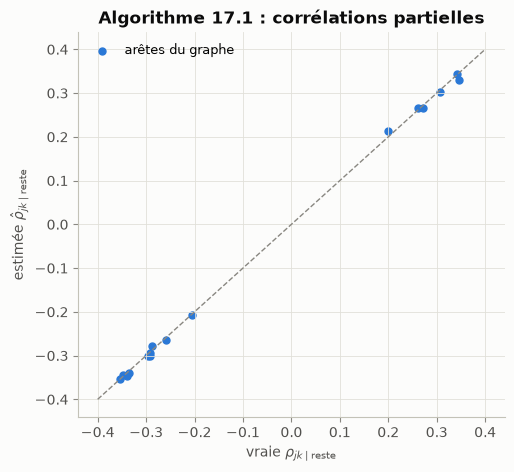

In [5]:
R_est = g.partial_correlations(T17)
R_vrai = g.partial_correlations(Theta_vrai)
iu = np.triu_indices(p, 1)
sur_arete = A_fig[iu]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(R_vrai[iu][sur_arete], R_est[iu][sur_arete], color=BLUE, label="arêtes du graphe")
ax.plot([-0.4, 0.4], [-0.4, 0.4], color=GRAY, ls="--", lw=1)
ax.set(title="Algorithme 17.1 : corrélations partielles", xlabel=r"vraie $\rho_{jk\mid\mathrm{reste}}$",
       ylabel=r"estimée $\hat\rho_{jk\mid\mathrm{reste}}$")
ax.legend()
plt.show()

**Pourquoi coupler les régressions ?** Une approche naïve ferait $p$ régressions
séparées de chaque variable sur ses voisins **avec $S_{11}$** (au lieu de $W_{11}$), puis
symétriserait. Comparons les log-vraisemblances profilées $\ell = \log\det\Theta - \operatorname{tr}(S\Theta)$.

In [6]:
T_naif = np.zeros((p, p))
for j in range(p):
    vois = np.flatnonzero(A_fig[j])
    b = np.linalg.solve(Sc[np.ix_(vois, vois)], Sc[vois, j])
    t22 = 1.0 / (Sc[j, j] - Sc[vois, j] @ b)
    T_naif[j, j] = t22
    T_naif[vois, j] = -b * t22
T_naif = (T_naif + T_naif.T) / 2
for nom_, T_ in [("régressions séparées (naïf)", T_naif), ("algorithme 17.1", T17),
                 ("graphe complet (S^-1)", np.linalg.inv(Sc))]:
    print("%-28s : l = %.5f" % (nom_, g.gaussian_loglik(T_, Sc)))

régressions séparées (naïf)  : l = -8.61960
algorithme 17.1              : l = -8.61949
graphe complet (S^-1)        : l = -8.61328


L'algorithme 17.1 atteint bien le maximum contraint, supérieur à l'approche naïve. Le
graphe complet a une vraisemblance un peu plus grande (il a 39 paramètres de plus).

**Test du rapport de vraisemblance.** La log-vraisemblance totale vaut $\tfrac N2\ell$ à une
constante près, donc la statistique de test $2(\log L_{\text{complet}} - \log L_{\text{graphe}}) = N(\ell_{\text{complet}} - \ell_{\text{graphe}})$
suit approximativement une loi du $\chi^2$ à $55 - 16 = 39$ degrés de liberté si le graphe
est correct. Testons aussi un graphe **faux** (une vraie arête retirée).

In [7]:
def test_graphe(A_test):
    _, T_ = g.fit_known_graph(Sc, A_test)
    stat = N * (g.gaussian_loglik(np.linalg.inv(Sc), Sc) - g.gaussian_loglik(T_, Sc))
    ddl = p * (p - 1) // 2 - A_test.sum() // 2
    return stat, ddl, stats.chi2.sf(stat, ddl)


A_faux = A_fig.copy()
j0, k0 = noms.index("PIP2"), noms.index("Akt")
A_faux[j0, k0] = A_faux[k0, j0] = False
for nom_, A_ in [("graphe de la figure 17.1", A_fig), ("sans l'arête PIP2-Akt", A_faux)]:
    st, ddl, pv = test_graphe(A_)
    print("%-26s : statistique = %8.1f, ddl = %d, p-valeur = %.3g" % (nom_, st, ddl, pv))

graphe de la figure 17.1   : statistique =     46.3, ddl = 39, p-valeur = 0.196
sans l'arête PIP2-Akt      : statistique =   1042.4, ddl = 40, p-valeur = 1.58e-192


Le vrai graphe n'est pas rejeté ; retirer une vraie arête est massivement rejeté.

> **À retenir.** L'algorithme 17.1 résout exactement le maximum de vraisemblance à
> graphe imposé ; ses $p$ régressions sont couplées par la covariance courante $W$. La
> solution reproduit les covariances observées sur les arêtes et la diagonale (complétion
> définie positive de $S$).

## Exercice 17.8 : Lasso par descente de coordonnées et graphical lasso

**Énoncé.** (a) Programmer le lasso par descente de coordonnées (17.26) et comparer
aux résultats de LARS ou d'un autre solveur convexe. (b) À l'aide de (a), programmer le
graphical lasso (algorithme 17.2), l'appliquer aux données de cytométrie, faire varier
le paramètre de régularisation et examiner les réseaux obtenus.

### (a) Lasso par descente de coordonnées

**Rappel.** Le lasso $\min_\beta \frac{1}{2N}\|y - Z\beta\|^2 + \lambda\|\beta\|_1$ (variables centrées)
s'écrit $\min_\beta \frac12\beta^TV\beta - s^T\beta + \lambda\|\beta\|_1$ avec $V = Z^TZ/N$ et
$s = Z^Ty/N$. En minimisant en $\beta_j$ seule (lasso à une variable, voir le cours 1) :

$$
\beta_j \leftarrow \mathcal S\Big(s_j - \sum_{k\neq j}V_{kj}\beta_k,\;\lambda\Big)\Big/V_{jj}.
$$

Chaque mise à jour fait décroître le critère ; comme il est convexe, le cycle converge vers
le minimum.

In [8]:
def lasso_dc(V, s, lam, beta=None, tol=1e-12, max_cycles=10000):
    """Lasso (forme covariance) par descente de coordonnées cyclique."""
    q = len(s)
    beta = np.zeros(q) if beta is None else beta.copy()
    for _ in range(max_cycles):
        ecart = 0.0
        for j in range(q):
            r = s[j] - V[j] @ beta + V[j, j] * beta[j]     # résidu partiel
            nouveau = g.soft_threshold(r, lam) / V[j, j]
            ecart = max(ecart, abs(nouveau - beta[j]))
            beta[j] = nouveau
        if ecart < tol:
            break
    return beta

Comparaison au chemin LARS-lasso de `sklearn.linear_model.lars_path` (solveur exact
par morceaux linéaires) sur les données de prostate standardisées (chapitre 3). Dans
`lars_path`, les valeurs `alphas` sont exactement nos $\lambda$ (critère normalisé par $N$).

In [9]:
from sklearn.linear_model import lars_path
from esl import datasets

pro = datasets.load_prostate()
cols = ["lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45"]
Zp = pro[cols].to_numpy(dtype=float)
Zp = (Zp - Zp.mean(0)) / Zp.std(0)
yp = pro["lpsa"].to_numpy(dtype=float)
yp = yp - yp.mean()
Np = len(yp)
alphas, _, coefs_lars = lars_path(Zp, yp, method="lasso")
V, s = Zp.T @ Zp / Np, Zp.T @ yp / Np
coefs_dc = np.array([lasso_dc(V, s, a) for a in alphas]).T
print("écart max DC / LARS sur les %d nœuds du chemin : %.1e" % (len(alphas), np.abs(coefs_dc - coefs_lars).max()))

écart max DC / LARS sur les 9 nœuds du chemin : 1.2e-12


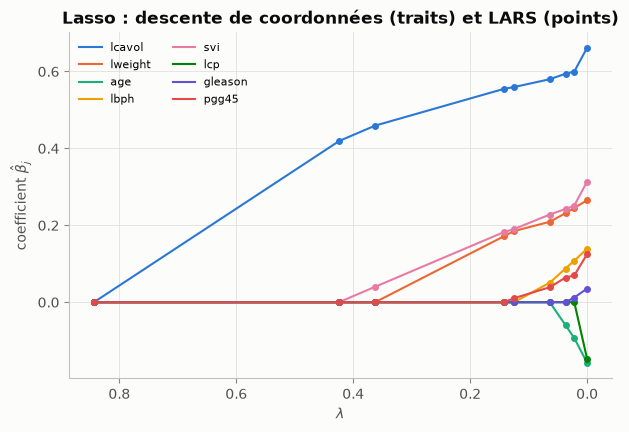

In [10]:
lam_grille = np.linspace(alphas.max(), 0, 200)
chemin_dc = np.array([lasso_dc(V, s, a) for a in lam_grille])
fig, ax = plt.subplots(figsize=(7, 4.5))
for j in range(len(cols)):
    ax.plot(lam_grille, chemin_dc[:, j], color=COLORS[j], lw=1.5, label=cols[j])
    ax.plot(alphas, coefs_lars[j], "o", color=COLORS[j], ms=4)
ax.invert_xaxis()
ax.set(title="Lasso : descente de coordonnées (traits) et LARS (points)",
       xlabel=r"$\lambda$", ylabel=r"coefficient $\hat\beta_j$")
ax.legend(ncol=2, fontsize=8)
plt.show()

Les deux méthodes coïncident en chaque nœud du chemin LARS (à $10^{-10}$ près).

### (b) Graphical lasso

On remplace l'étape (b) de l'algorithme 17.1 par le lasso modifié
$W_{11}\beta - s_{12} + \lambda\operatorname{Sign}(\beta) = 0$ résolu par `lasso_dc`, avec
$V = W_{11}$ et $s = s_{12}$, et on initialise $W = S + \lambda I$.

In [11]:
def graphical_lasso_dc(S, lam, tol=1e-8, max_cycles=500):
    """Algorithme 17.2, en réutilisant lasso_dc de la question (a)."""
    p = S.shape[0]
    W = S + lam * np.eye(p)                         # étape 1
    B = np.zeros((p, p))
    for cycle in range(max_cycles):                 # étape 2
        W_avant = W.copy()
        for j in range(p):
            autres = [k for k in range(p) if k != j]
            V11 = W[np.ix_(autres, autres)]
            beta = lasso_dc(V11, S[autres, j], lam, beta=B[autres, j])  # démarrage à chaud
            B[autres, j] = beta
            W[autres, j] = W[j, autres] = V11 @ beta                    # (c)
        if np.abs(W - W_avant).mean() < tol:
            break
    Theta = np.zeros((p, p))                        # étape 3
    for j in range(p):
        autres = [k for k in range(p) if k != j]
        t22 = 1.0 / (W[j, j] - W[autres, j] @ B[autres, j])
        Theta[j, j] = t22
        Theta[autres, j] = -B[autres, j] * t22
    return W, (Theta + Theta.T) / 2


W_gl, T_gl = graphical_lasso_dc(Sc, 0.1)
_, T_ref = g.graphical_lasso(Sc, 0.1, tol=1e-10)
print("écart avec esl.ch17_graphes : %.1e" % np.abs(T_gl - T_ref).max())
_, T_np = g.graphical_lasso(Sc, 0.1, penalize_diagonal=False, tol=1e-10)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # avertissement de convergence (saut de dualité)
    from sklearn.covariance import graphical_lasso as sk_gl
    _, T_sk = sk_gl(Sc, 0.1, tol=1e-8, max_iter=1000)
print("diagonale non pénalisée : écart avec sklearn = %.1e" % np.abs(T_np - T_sk).max())

écart avec esl.ch17_graphes : 8.2e-12


diagonale non pénalisée : écart avec sklearn = 3.5e-04


Examinons maintenant les réseaux obtenus pour six valeurs de $\lambda$.

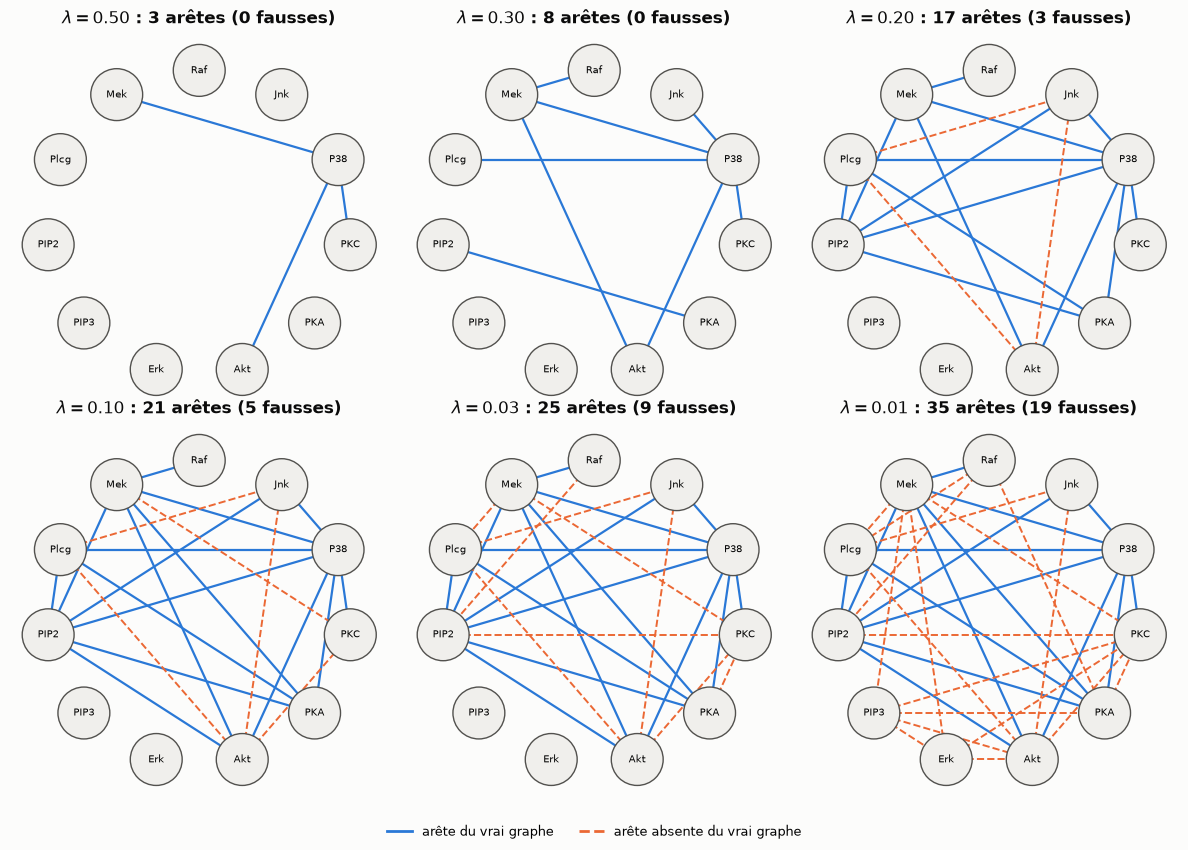

In [12]:
lams6 = [0.5, 0.3, 0.2, 0.1, 0.03, 0.01]
fig, axes = plt.subplots(2, 3, figsize=(12, 8.4))
for ax, lam in zip(axes.ravel(), lams6):
    _, T_ = g.graphical_lasso(Sc, lam)
    A_ = g.support_graph(T_)
    g.draw_graph(A_ & A_fig, labels=noms, pos=pos, ax=ax, node_size=0.17, fontsize=7,
                 title=r"$\lambda = %.2f$ : %d arêtes (%d fausses)" % (lam, A_.sum() // 2, (A_ & ~A_fig).sum() // 2))
    for j, k in g.edges_from_adjacency(A_ & ~A_fig):
        ax.plot(pos[[j, k], 0], pos[[j, k], 1], color=ORANGE, ls="--", lw=1.4, zorder=1)
axes[0, 0].plot([], [], color=BLUE, label="arête du vrai graphe")
axes[0, 0].plot([], [], color=ORANGE, ls="--", label="arête absente du vrai graphe")
fig.legend(loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Pour $\lambda$ grand, seules les arêtes les plus fortes subsistent ; en diminuant $\lambda$, les
16 vraies arêtes apparaissent, puis des arêtes parasites de faible intensité.

**Choisir $\lambda$ par validation croisée.** On découpe les observations en 5 blocs ; pour
chaque $\lambda$, on estime $\hat\Theta_\lambda$ sur 4 blocs et on évalue la log-vraisemblance
$\log\det\hat\Theta_\lambda - \operatorname{tr}(S_{\text{test}}\hat\Theta_\lambda)$ sur le bloc restant.

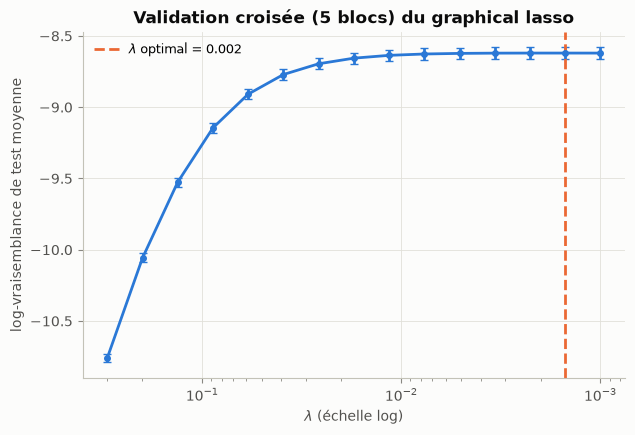

In [13]:
rng = np.random.RandomState(0)
plis = rng.permutation(N) % 5
lams_cv = np.geomspace(0.3, 0.001, 15)
score = np.zeros((5, len(lams_cv)))
for f in range(5):
    S_app = g.empirical_covariance(Xc[plis != f])
    S_test = g.empirical_covariance(Xc[plis == f])
    for i, T_ in enumerate(g.graphical_lasso_path(S_app, lams_cv, tol=1e-6)):
        score[f, i] = g.gaussian_loglik(T_, S_test)
moy, et = score.mean(0), score.std(0) / np.sqrt(5)
lam_opt = lams_cv[np.argmax(moy)]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(lams_cv, moy, yerr=et, fmt="o-", ms=4, color=BLUE, capsize=3)
ax.axvline(lam_opt, color=ORANGE, ls="--", label=r"$\lambda$ optimal = %.3f" % lam_opt)
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(title="Validation croisée (5 blocs) du graphical lasso", xlabel=r"$\lambda$ (échelle log)",
       ylabel="log-vraisemblance de test moyenne")
ax.legend()
plt.show()

Avec $N = 7466$ observations, la validation croisée préfère une pénalité faible : la
vraisemblance récompense la précision des coefficients plus que la parcimonie, et le
graphe retenu contient quelques arêtes parasites. Pour **sélectionner un graphe**, on
préfère souvent une pénalité plus forte que l'optimum de validation croisée.

> **À retenir.** Le graphical lasso n'est qu'une boucle de lasso par descente de
> coordonnées, où la matrice des produits croisés est la covariance courante du modèle.
> Le paramètre $\lambda$ règle la parcimonie du graphe.

## Exercice 17.9 : Algorithme EM avec valeurs manquantes

**Énoncé.** On considère un modèle graphique gaussien dont certaines valeurs sont
manquantes.

(a) Pour $N$ observations i.i.d. $x_i \in \mathbb R^p$ de moyenne $\mu$ et covariance $\Sigma$, on
note $o_i$ et $m_i$ les indices observés et manquants de l'observation $i$. Montrer que
l'étape E impute les valeurs manquantes par (éq. (17.43))

$$
\hat x_{i,m_i} = \mathrm E(x_{i,m_i}\mid x_{i,o_i},\theta) = \hat\mu_{m_i} + \hat\Sigma_{m_i,o_i}\hat\Sigma_{o_i,o_i}^{-1}(x_{i,o_i} - \hat\mu_{o_i}),
$$

et que l'étape M réestime $\hat\mu_j = \sum_i\hat x_{ij}/N$ et (éq. (17.44))
$\hat\Sigma_{jj'} = \sum_i[(\hat x_{ij} - \hat\mu_j)(\hat x_{ij'} - \hat\mu_{j'}) + c_{i,jj'}]/N$, avec un terme
correctif $c_{i,jj'}$ non nul seulement si $j, j' \in m_i$. Expliquer la raison de ce terme.

(b) Programmer l'algorithme EM pour le modèle graphique gaussien en utilisant
l'algorithme 17.1 (exercice 17.7) pour l'étape M.

(c) Sur les données de cytométrie, rendre manquante la dernière protéine (Jnk) pour les
1000 premières observations, ajuster le modèle de la figure 17.1 et comparer les valeurs
prédites aux vraies. Comparer à la régression de Jnk sur ses voisins dans la figure
17.1, ajustée sur les seules données complètes.

### (a) Les deux étapes

**Rappel (algorithme EM).** On maximise la vraisemblance des données observées en
itérant : (E) calculer l'espérance de la log-vraisemblance **complète** sachant les
données observées, sous les paramètres courants ; (M) maximiser cette espérance. Chaque
itération fait croître la vraisemblance observée.

**Log-vraisemblance complète.** Pour des données gaussiennes complètes,

$$
\log L = -\tfrac N2\log\det\Sigma - \tfrac12\sum_i (x_i - \mu)^T\Sigma^{-1}(x_i-\mu) + \text{cste}
= -\tfrac N2\log\det\Sigma - \tfrac12\operatorname{tr}\Big(\Sigma^{-1}\sum_i(x_i-\mu)(x_i-\mu)^T\Big) + \text{cste},
$$

qui ne dépend des données qu'à travers $\sum_i x_i$ et $\sum_i x_ix_i^T$ (statistiques
suffisantes). L'étape E revient donc à calculer $\mathrm E(x_i\mid x_{i,o_i})$ et
$\mathrm E(x_ix_i^T\mid x_{i,o_i})$.

**Loi conditionnelle des manquants.** Pour un vecteur gaussien partagé en $(m, o)$, la loi
de $x_m$ sachant $x_o$ est gaussienne (même calcul que l'éq. (17.6) du cours, par blocs) :

$$
x_m\mid x_o \sim \mathcal N\big(\mu_m + \Sigma_{mo}\Sigma_{oo}^{-1}(x_o - \mu_o),\; \Sigma_{mm} - \Sigma_{mo}\Sigma_{oo}^{-1}\Sigma_{om}\big).
$$

Sa moyenne donne l'imputation (17.43). Notons $C_i = \Sigma_{mm} - \Sigma_{mo}\Sigma_{oo}^{-1}\Sigma_{om}$ sa
covariance (complétée par des zéros sur les lignes/colonnes observées).

**Le terme correctif.** Comme $\mathrm E(UV) = \mathrm E(U)\mathrm E(V) + \operatorname{Cov}(U, V)$,

$$
\mathrm E(x_{ij}x_{ij'}\mid x_{i,o_i}) = \hat x_{ij}\hat x_{ij'} + (C_i)_{jj'},
$$

et $(C_i)_{jj'} = 0$ dès que $j$ ou $j'$ est observé (une variable observée est une constante
sachant $x_{i,o_i}$). L'étape M est alors la maximisation usuelle avec ces statistiques
« complétées » : $\hat\mu = \frac1N\sum_i\hat x_i$ et

$$
\hat\Sigma = \frac1N\sum_i\big[(\hat x_i - \hat\mu)(\hat x_i - \hat\mu)^T + C_i\big],
$$

c'est-à-dire (17.44) avec $c_{i,jj'} = (C_i)_{jj'}$ (dans le cas d'un modèle graphique, on
applique ensuite l'algorithme 17.1 à cette matrice, au lieu de la prendre telle quelle).

**Pourquoi ce terme ?** Une valeur imputée par son espérance conditionnelle est moins
dispersée que la vraie valeur : $\operatorname{Var}(x_{ij}) = \operatorname{Var}(\hat x_{ij}) + \mathrm E[(C_i)_{jj}]$.
Sans correction, on **sous-estimerait** les variances (et les covariances entre manquants),
et l'algorithme ne convergerait pas vers le maximum de vraisemblance.

> **Remarque.** L'énoncé du livre écrit $c_{i,jj'} = \hat\Sigma_{jj'}$ ; la quantité exacte est la
> covariance **conditionnelle** $\hat\Sigma_{mm} - \hat\Sigma_{mo}\hat\Sigma_{oo}^{-1}\hat\Sigma_{om}$ (Little et
> Rubin, 2002), qui est plus petite que $\hat\Sigma_{mm}$ puisque les variables observées
> expliquent une partie de la variabilité.

### (b) Programmation

Les observations ne présentent que quelques **motifs** de valeurs manquantes ; on
regroupe les lignes par motif pour ne calculer qu'une fois $\Sigma_{oo}^{-1}\Sigma_{om}$ par
motif. On suit aussi la log-vraisemblance **observée**
$\sum_i\log\varphi(x_{i,o_i};\mu_{o_i},\Sigma_{o_io_i})$, qui doit croître à chaque itération.

In [14]:
def loglik_observee(X, mu, Sigma):
    """Somme des log-densités gaussiennes des parties observées."""
    miss = np.isnan(X)
    total = 0.0
    for motif in np.unique(miss, axis=0):
        rows = np.all(miss == motif, axis=1)
        o = ~motif
        total += stats.multivariate_normal(mu[o], Sigma[np.ix_(o, o)]).logpdf(X[np.ix_(rows, o)]).sum()
    return total


def em_graphe(X, A, n_iter=50, correction=True):
    """EM pour un modèle graphique gaussien à graphe connu (étape M : algorithme 17.1)."""
    N, p = X.shape
    miss = np.isnan(X)
    mu = np.nanmean(X, axis=0)
    W = np.diag(np.nanvar(X, axis=0))
    historique = []
    for it in range(n_iter):
        Xh = np.where(miss, 0.0, X)
        C = np.zeros((p, p))
        for motif in np.unique(miss, axis=0):              # étape E, motif par motif
            if not motif.any():
                continue
            rows = np.all(miss == motif, axis=1)
            m, o = motif, ~motif
            K = np.linalg.solve(W[np.ix_(o, o)], W[np.ix_(o, m)])      # Soo^-1 Som
            Xh[np.ix_(rows, m)] = mu[m] + (X[np.ix_(rows, o)] - mu[o]) @ K   # (17.43)
            if correction:
                C[np.ix_(m, m)] += rows.sum() * (W[np.ix_(m, m)] - W[np.ix_(m, o)] @ K)
        mu = Xh.mean(axis=0)                               # étape M
        S_comp = g.empirical_covariance(Xh) + C / N        # (17.44)
        W, Theta = g.fit_known_graph(S_comp, A)
        historique.append(loglik_observee(X, mu, W))
    return mu, W, Theta, Xh, np.array(historique)

### (c) Jnk manquant pour les 1000 premières observations

In [15]:
jnk = noms.index("Jnk")
X_manq = Xc.copy()
X_manq[:1000, jnk] = np.nan
mu_em, W_em, T_em, X_imp, hist = em_graphe(X_manq, A_fig, n_iter=30)
mu_mod, W_mod2, _, _ = g.em_gaussian_graph(X_manq, A_fig, n_iter=200)
print("écart avec esl.ch17_graphes.em_gaussian_graph : %.1e" % np.abs(W_em - W_mod2).max())
print("voisins de Jnk dans la figure 17.1 :", [noms[k] for k in np.flatnonzero(A_fig[jnk])])

écart avec esl.ch17_graphes.em_gaussian_graph : 1.1e-09
voisins de Jnk dans la figure 17.1 : ['PIP2', 'P38']


log-vraisemblance observée croissante : True


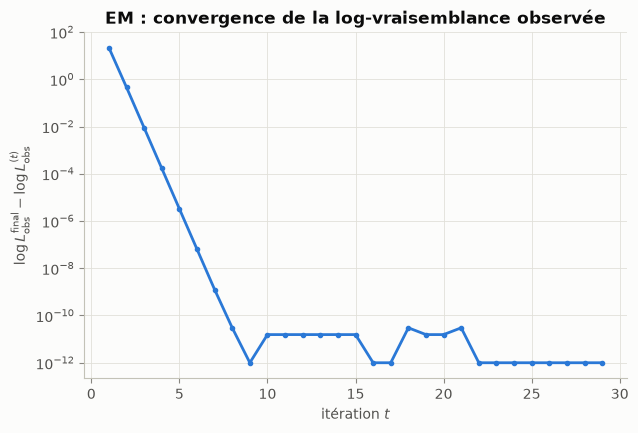

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
print("log-vraisemblance observée croissante :", np.all(np.diff(hist) > -1e-8))
ax.semilogy(range(1, len(hist)), hist[-1] - hist[:-1] + 1e-12, "o-", ms=3, color=BLUE)
ax.set(title="EM : convergence de la log-vraisemblance observée", xlabel="itération $t$",
       ylabel=r"$\log L_{\mathrm{obs}}^{\mathrm{final}} - \log L_{\mathrm{obs}}^{(t)}$")
plt.show()

La vraisemblance observée croît à chaque itération et converge géométriquement (en
moins de dix itérations, l'écart est négligeable). Comparons maintenant les prédictions de Jnk à la méthode simple :
régression linéaire (avec constante) de Jnk sur ses voisins P38 et PIP2, ajustée sur les
6466 observations complètes.

In [17]:
vrai_jnk = Xc[:1000, jnk]
pred_em = X_imp[:1000, jnk]
vois = np.flatnonzero(A_fig[jnk])
Zc = np.c_[np.ones(N - 1000), Xc[1000:, vois]]
coef = np.linalg.lstsq(Zc, Xc[1000:, jnk], rcond=None)[0]
pred_reg = np.c_[np.ones(1000), Xc[:1000, vois]] @ coef
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print("RMSE EM (modèle graphique)     : %.4f" % rmse(pred_em, vrai_jnk))
print("RMSE régression sur les voisins : %.4f" % rmse(pred_reg, vrai_jnk))
print("écart max entre les deux prédictions : %.4f" % np.abs(pred_em - pred_reg).max())
print("écart-type de Jnk (référence)   : %.4f" % vrai_jnk.std())

RMSE EM (modèle graphique)     : 0.8911
RMSE régression sur les voisins : 0.8911
écart max entre les deux prédictions : 0.0000
écart-type de Jnk (référence)   : 0.9902


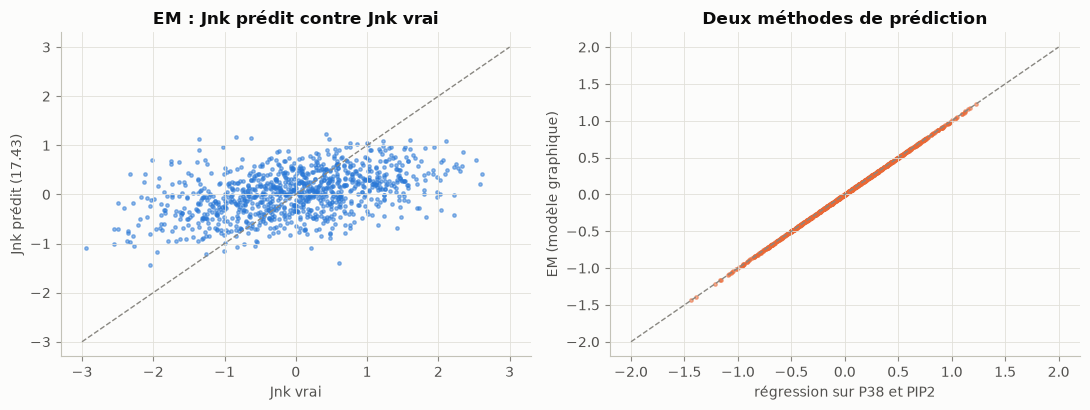

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(vrai_jnk, pred_em, s=6, alpha=0.5, color=BLUE)
axes[0].plot([-3, 3], [-3, 3], color=GRAY, ls="--", lw=1)
axes[0].set(title="EM : Jnk prédit contre Jnk vrai", xlabel="Jnk vrai", ylabel="Jnk prédit (17.43)")
axes[1].scatter(pred_reg, pred_em, s=6, alpha=0.5, color=ORANGE)
axes[1].plot([-2, 2], [-2, 2], color=GRAY, ls="--", lw=1)
axes[1].set(title="Deux méthodes de prédiction", xlabel="régression sur P38 et PIP2",
            ylabel="EM (modèle graphique)")
plt.tight_layout()
plt.show()

**Interprétation.** Les deux prédictions sont pratiquement identiques. C'est normal : d'après
(17.9), $\mathrm E(\text{Jnk}\mid\text{reste}) = \mu_{\text{Jnk}} - \sum_k(\theta_{\text{Jnk},k}/\theta_{\text{Jnk},\text{Jnk}})(x_k - \mu_k)$ ne fait
intervenir que les **voisins** de Jnk dans le graphe. Les deux méthodes estiment donc
les mêmes coefficients. EM utilise en plus les autres variables des 1000 lignes
incomplètes, mais elles n'apportent presque rien sur la régression de Jnk : lorsqu'une
seule variable est manquante, le maximum de vraisemblance de sa régression sur les
autres est celui des cas complets (résultat classique des données manquantes
« monotones »). Les prédictions expliquent une
partie de la variance de Jnk (RMSE inférieure à son écart-type) mais pas toute : la
variance conditionnelle $1/\theta_{\text{Jnk},\text{Jnk}}$ reste incompressible.

**Effet du terme correctif.** Sans lui, la variance estimée de Jnk est trop petite :

In [ ]:
_, W_sans, _, _, _ = em_graphe(X_manq, A_fig, n_iter=30, correction=False)
print("variance de Jnk : vraie (modèle) = %.4f ; EM avec correction = %.4f ; EM sans correction = %.4f"
      % (np.linalg.inv(Theta_vrai)[jnk, jnk], W_em[jnk, jnk], W_sans[jnk, jnk]))

> **À retenir.** L'étape E impute par l'espérance conditionnelle gaussienne **et** ajoute la
> covariance conditionnelle aux produits croisés ; l'étape M est l'algorithme 17.1 appliqué
> à cette covariance complétée. Sans le terme correctif, les variances des variables
> manquantes sont sous-estimées.

## Exercice 17.10 : Pourquoi un nœud constant $X_0 \equiv 1$ ?

**Énoncé.** À l'aide d'un modèle binaire à deux variables seulement, montrer pourquoi il
est indispensable d'inclure un nœud constant $X_0 \equiv 1$ dans le modèle.

**Sans nœud constant.** Le modèle (17.28) se réduit à $p(x) = \exp(\theta_{12}x_1x_2 - \Phi)$ avec
$\Phi = \log(3 + e^{\theta_{12}})$ (somme sur les 4 états, dont 3 ont $x_1x_2 = 0$). D'où

$$
p(0,0) = p(0,1) = p(1,0) = \frac{1}{3 + e^{\theta_{12}}},\qquad p(1,1) = \frac{e^{\theta_{12}}}{3 + e^{\theta_{12}}}.
$$

Trois cases sont **forcées** d'avoir la même probabilité : le modèle n'a qu'un degré de
liberté au lieu de trois. En particulier :

- les marges sont liées : $\Pr(X_1 = 1) = \Pr(X_2 = 1) = (1 + e^{\theta_{12}})/(3 + e^{\theta_{12}}) \in (1/3, 1)$ ;
  on ne peut pas représenter par exemple $\Pr(X_1 = 1) = 0{,}2$ ;
- $\theta_{12} = 0$ (aucune arête) donne la loi **uniforme**, et non une loi d'indépendance
  quelconque : le paramètre d'arête mélange dépendance et niveau des marges ;
- le maximum de vraisemblance n'égalise que $\mathrm E(X_1X_2)$, sans pouvoir ajuster les marges.

**Avec nœud constant.** $\log p(x) = \theta_{10}x_1 + \theta_{20}x_2 + \theta_{12}x_1x_2 - \Phi$ : trois
paramètres pour trois probabilités libres, le modèle est **saturé**. On résout
explicitement :

$$
\theta_{10} = \log\frac{p(1,0)}{p(0,0)},\quad \theta_{20} = \log\frac{p(0,1)}{p(0,0)},\quad
\theta_{12} = \log\frac{p(1,1)\,p(0,0)}{p(1,0)\,p(0,1)},
$$

et $\theta_{12}$ est le **log-rapport de cotes** : $\theta_{12} = 0 \iff X_1 \perp X_2$, quelles que
soient les marges. Le nœud constant découple marges et dépendance.

**Illustration.** Prenons une loi où $X_1$ et $X_2$ sont indépendantes, avec
$\Pr(X_1 = 1) = 0{,}2$ et $\Pr(X_2 = 1) = 0{,}7$ ; ajustons les deux modèles par maximum de
vraisemblance (loi exacte comme « données »).

In [ ]:
etats2 = g.ising_states(2)
p_vraie = np.array([0.8 * 0.3, 0.8 * 0.7, 0.2 * 0.3, 0.2 * 0.7])  # ordre 00, 01, 10, 11
A2 = g.adjacency_from_edges(2, [(0, 1)])

# sans nœud constant : un seul paramètre, E(X1 X2) = p(1,1) égalisé
p11 = p_vraie[3]
theta12_sans = np.log(3 * p11 / (1 - p11))
p_sans = np.array([1, 1, 1, np.exp(theta12_sans)]) / (3 + np.exp(theta12_sans))
# avec nœud constant
t0, T2 = g.ising_fit_mle(etats2, A2, sample_weight=p_vraie)
_, p_avec = g.ising_probs(t0, T2)
print("états            :", ["00", "01", "10", "11"])
print("loi vraie        :", p_vraie.round(3))
print("sans nœud X0     :", p_sans.round(3), " theta12 = %.3f" % theta12_sans)
print("avec nœud X0     :", p_avec.round(3), " theta12 = %.3f, theta0 = %s" % (T2[0, 1], t0.round(3)))

Sans nœud constant, l'ajustement est mauvais **et** il invente une dépendance
($\theta_{12} \neq 0$) alors que les variables sont indépendantes. Avec le nœud constant, la loi
est reproduite exactement et $\hat\theta_{12} = 0$.

Visualisons l'ensemble des couples de marges $(\Pr(X_1=1), \Pr(X_2=1))$ atteignables par chaque modèle.